# From genes to prognosis: predicting breast-cancer mortality from clinical and genomic data (METABRIC)

**Machine Learning 1 capstone, Tek-Up, ING-4 SDIA, 2026–2027**
**Team PrognoGen:** Oumaima Hafiane, Imen Hichri
**Notebook 03: Modeling (Phase 5 onwards)**

# 5. Baseline Models

## Objective
Train at least four supervised models with their default hyperparameters, estimate their performance with 5-fold cross-validation on the training set, and compare them on the feature sets defined in section 4.14. The test set is not used in this section: it is kept for the final evaluation in Phase 6.

## Protocol

| Decision | Reason |
|---|---|
| Every model is a `Pipeline`: the Phase 4 preprocessor first, then the classifier | In each fold the imputer, scaler and encoder are fitted on the 4 training folds only, so the validation fold never influences them |
| `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`, the same folds for every model | Each fold keeps 33% of class 1, and all models are tested on exactly the same patients, so the comparison is fair |
| Default hyperparameters, with three exceptions: class weights, `max_iter` of Logistic Regression, and `random_state` / `n_jobs` | Class weights are the imbalance decision of Phase 4; `max_iter` only gives the solver enough iterations to converge; the others fix reproducibility and speed. None of them is tuning |
| Primary metric ROC-AUC; also PR-AUC, and recall and F1 of class 1 | ROC-AUC was chosen in Phase 1; PR-AUC focuses on the patients who died; recall and F1 use the default decision threshold of each model |
| Six models: Logistic Regression, KNN, SVM, Random Forest, XGBoost, LightGBM | One model from each family of the course (linear, distance-based, kernel, tree ensemble, two boosting libraries) |
| Feature set A (NPI) is evaluated as the raw score, without a model | ROC-AUC depends only on how patients are ranked, and the NPI is already a risk score. This is exactly how oncologists use it |
| Sets B (clinical) and C (clinical + genes + mutations) are evaluated with all six models | The gap between B and C answers the central question |

## 5.1 Setup

**What the next cell does:** imports the libraries and sets the global configuration.
- `SEED = 42` fixes every random choice (split, folds, models).
- `CB` (aqua) and `CC` (violet) are the colours of feature sets B and C in the figures of this section. Blue and orange stay reserved for the two classes, as in the previous notebooks.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

from sklearn import set_config
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.metrics import roc_auc_score, average_precision_score

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')
pd.set_option('display.max_colwidth', None)
set_config(display='diagram')

C0, C1 = '#2a78d6', '#eb6834'          # class 0 (blue), class 1 (orange)
CB, CC = '#1baf7a', '#6250d6'          # feature set B (aqua), feature set C (violet)

## 5.2 Loading the cleaned data and rebuilding the split

**What the next cell does:** loads the cleaned table saved at the end of Phase 4 (section 4.16) and rebuilds exactly the same train/test split.
- `metabric_clean.csv` contains the 1,902 patients after the row cleaning, the column removals, the 0/1 mutation flags and the two engineered features. Its last column is the target.
- The three column lists (clinical, gene expression, mutations) are rebuilt from the header of the raw file, as in Phase 2.
- `cohort` is read back as a number, so it is converted to text again: it is a group label, not a quantity.
- The split uses the same arguments as section 4.6. The `assert` checks that the result is identical: 1,521 training patients, 497 of them in class 1.

In [2]:
CLEAN_PATH = '../data/processed/metabric_clean.csv'
RAW_PATH = '../data/raw/METABRIC_RNA_Mutation.csv'

clean = pd.read_csv(CLEAN_PATH)
y = clean.pop('target')
X = clean
X['cohort'] = X['cohort'].astype(str)

raw_cols = pd.read_csv(RAW_PATH, nrows=0).columns
clinical_cols = raw_cols[:31].tolist()
mut_cols = [c for c in raw_cols if c.endswith('_mut')]
expr_cols = [c for c in raw_cols if c not in clinical_cols and c not in mut_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

assert X.shape == (1902, 687)
assert (len(X_train), int(y_train.sum()), len(X_test), int(y_test.sum())) == (1521, 497, 381, 125)
print(f"X: {X.shape} | X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Class 1 share: train {y_train.mean():.1%}, test {y_test.mean():.1%}")

X: (1902, 687) | X_train: (1521, 687) | X_test: (381, 687)
Class 1 share: train 32.7%, test 32.8%


## 5.3 Preprocessor and feature sets (from Phase 4)

**What the next cell does:** rebuilds the objects defined in sections 4.7, 4.9, 4.10 and 4.14, with the same code, so that this notebook runs on its own. In the final notebook (`04_final_pipeline.ipynb`) they appear only once, in section 4.
- `mut_keep`: the genes mutated in at least 5% of the training patients.
- The five column groups and `make_preprocessor(keep=...)`, which builds the `ColumnTransformer` for a given set of columns.
- `feature_sets`: A (NPI only), B (clinical) and C (clinical + genes + mutations).

The `assert` checks that the full preprocessor still produces the 579 columns obtained in Phase 4.

In [3]:
mut_freq = X_train[mut_cols].mean() * 100
mut_keep = mut_freq[mut_freq >= 5].sort_values(ascending=False).index.tolist()

num_cols = ['age_at_diagnosis', 'tumor_size', 'lymph_nodes_examined_positive', 'mutation_count',
            'nottingham_prognostic_index', 'neoplasm_histologic_grade', 'proliferation_score'] + expr_cols
stage_col = ['tumor_stage']
ord_col = ['cellularity']
nom_cols = ['type_of_breast_surgery', 'er_status', 'her2_status', 'pr_status',
            'inferred_menopausal_state', 'primary_tumor_laterality', 'pam50_+_claudin-low_subtype',
            'cohort', 'her2_status_measured_by_snp6', 'tumor_other_histologic_subtype',
            'integrative_cluster', '3-gene_classifier_subtype']
bin_cols = ['chemotherapy', 'hormone_therapy', 'radio_therapy', 'triple_negative'] + mut_keep


def make_preprocessor(keep=None):
    # keep = set of column names to use; None means all the columns
    def pick(cols):
        return cols if keep is None else [c for c in cols if c in keep]

    blocks = [
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), pick(num_cols)),
        ('stage', Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True)),
                            ('scaler', StandardScaler())]), pick(stage_col)),
        ('ord', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('encoder', OrdinalEncoder(categories=[['Low', 'Moderate', 'High']]))]), pick(ord_col)),
        ('nom', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), pick(nom_cols)),
        ('bin', 'passthrough', pick(bin_cols)),
    ]
    ct = ColumnTransformer([b for b in blocks if len(b[2]) > 0], remainder='drop')
    return ct.set_output(transform='pandas')


clinical_features = [c for c in X.columns if c not in expr_cols and c not in mut_cols and c != 'proliferation_score']
omics_features = expr_cols + ['proliferation_score'] + mut_keep
feature_sets = {
    'A. NPI only': ['nottingham_prognostic_index'],
    'B. Clinical': clinical_features,
    'C. Clinical + genes + mutations': clinical_features + omics_features,
}

preprocessor = make_preprocessor()
assert len(mut_keep) == 25
assert preprocessor.fit(X_train).transform(X_train.head()).shape[1] == 579
print(f"Kept mutation genes: {len(mut_keep)} | columns after the full preprocessor: 579")
print({name: len(cols) for name, cols in feature_sets.items()})

Kept mutation genes: 25 | columns after the full preprocessor: 579
{'A. NPI only': 1, 'B. Clinical': 24, 'C. Clinical + genes + mutations': 539}


## 5.4 Cross-validation folds and models

**What the next cell does:** defines the folds and the six classifiers.
- `cv` is created once and reused for every model and every feature set, so all of them are scored on the same five validation folds.
- `scale_pos_weight` (number of class 0 / number of class 1 in the training set, about 2.06) is the XGBoost form of class weights, as computed in section 4.13.
- `make_models()` returns new, unfitted models each time it is called. Default hyperparameters are kept except for the settings listed in the protocol table.
- `make_pipeline_for()` puts the preprocessor of a feature set in front of a classifier. This is the object that `cross_validate` fits, fold by fold, on the raw `X_train`.

| Model | Family | Settings changed from the default |
|---|---|---|
| Logistic Regression | Linear | `class_weight='balanced'`, `max_iter=5000` |
| KNN | Distance-based | none (k = 5) |
| SVM | Kernel (RBF) | `class_weight='balanced'` |
| Random Forest | Bagging of trees | `class_weight='balanced'` |
| XGBoost | Gradient boosting | `scale_pos_weight` |
| LightGBM | Gradient boosting | `class_weight='balanced'` |

KNN has no class-weight option, so the imbalance is not corrected for this model. Its ROC-AUC is not affected, because ROC-AUC does not depend on the threshold, but its recall at the default threshold will be lower.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()


def make_models():
    return {
        'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=5000, random_state=SEED),
        'KNN': KNeighborsClassifier(),
        'SVM (RBF)': SVC(class_weight='balanced', random_state=SEED),
        'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=SEED, n_jobs=-1),
        'XGBoost': XGBClassifier(scale_pos_weight=scale_pos_weight, eval_metric='logloss',
                                 random_state=SEED, n_jobs=-1),
        'LightGBM': LGBMClassifier(class_weight='balanced', random_state=SEED, n_jobs=-1, verbose=-1),
    }


def make_pipeline_for(feature_set, model):
    return Pipeline([('preprocessor', make_preprocessor(keep=set(feature_sets[feature_set]))),
                     ('classifier', model)])


print(f"scale_pos_weight = {scale_pos_weight:.3f}")
make_pipeline_for('B. Clinical', make_models()['Logistic Regression'])

scale_pos_weight = 2.060


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('stage', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defau

## 5.5 Reference: the NPI score alone (feature set A)

**What the next cell does:** measures how well the NPI, used as it is, ranks the patients of each validation fold.
- No model is trained: the NPI value of each patient is directly used as the risk score.
- ROC-AUC and PR-AUC are computed on each of the five validation folds, exactly the folds used for the models, so the numbers are directly comparable.
- Recall and F1 are not reported, because they need a yes/no decision and the NPI has no single threshold in our setting.

In [5]:
npi_auc, npi_ap = [], []
for train_idx, val_idx in cv.split(X_train, y_train):
    npi_val = X_train['nottingham_prognostic_index'].iloc[val_idx]
    y_val = y_train.iloc[val_idx]
    npi_auc.append(roc_auc_score(y_val, npi_val))
    npi_ap.append(average_precision_score(y_val, npi_val))

npi_auc, npi_ap = np.array(npi_auc), np.array(npi_ap)
print("ROC-AUC per fold:", np.round(npi_auc, 3))
print(f"NPI alone: ROC-AUC = {npi_auc.mean():.3f} +/- {npi_auc.std():.3f} | "
      f"PR-AUC = {npi_ap.mean():.3f} +/- {npi_ap.std():.3f}")
print(f"PR-AUC of a random ranking = share of class 1 = {y_train.mean():.3f}")

ROC-AUC per fold: [0.651 0.686 0.734 0.651 0.658]
NPI alone: ROC-AUC = 0.676 +/- 0.032 | PR-AUC = 0.515 +/- 0.010
PR-AUC of a random ranking = share of class 1 = 0.327


**Interpretation.** Used on its own, the NPI ranks a patient who died of the disease above one who did not in 67.6% of the pairs (ROC-AUC 0.676 ± 0.032), and its PR-AUC (0.515) is well above the 0.327 of a random ranking. The five folds range from 0.651 to 0.734, so the score depends noticeably on which patients fall in a fold: a gap smaller than about 0.03 between two methods should not be over-interpreted.

## 5.6 Cross-validation of the six models on feature sets B and C

**What the next cell does:** runs 5-fold cross-validation for each of the 12 combinations (6 models x 2 feature sets).
- `cross_validate` fits the whole pipeline on 4 folds and scores it on the fifth, five times. It is the same function as `cross_val_score` from the guide, but it returns several metrics at once and the fitting time.
- `scoring` lists the four metrics: `roc_auc` (primary), `average_precision` (PR-AUC), `recall` and `f1` (class 1, default threshold).
- `fold_auc` keeps the five ROC-AUC values of every combination, for the figures below.
- One line is printed per combination, so you can follow the progress. The cell takes a few minutes, mainly for the 489 gene columns of set C.

In [6]:
scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'recall': 'recall', 'f1': 'f1'}
rows, fold_auc = [], {}
start = time.time()

for fs_name in ['B. Clinical', 'C. Clinical + genes + mutations']:
    for model_name, model in make_models().items():
        res = cross_validate(make_pipeline_for(fs_name, model), X_train, y_train,
                             cv=cv, scoring=scoring, n_jobs=1)
        fold_auc[(fs_name, model_name)] = res['test_roc_auc']
        rows.append({
            'Feature set': fs_name, 'Model': model_name,
            'ROC-AUC mean': res['test_roc_auc'].mean(), 'ROC-AUC std': res['test_roc_auc'].std(),
            'PR-AUC mean': res['test_pr_auc'].mean(), 'PR-AUC std': res['test_pr_auc'].std(),
            'Recall mean': res['test_recall'].mean(), 'F1 mean': res['test_f1'].mean(),
            'Fit time (s)': res['fit_time'].mean(),
        })
        print(f"{fs_name:<32} {model_name:<20} ROC-AUC = {res['test_roc_auc'].mean():.3f} "
              f"+/- {res['test_roc_auc'].std():.3f}")

baseline_results = pd.DataFrame(rows)
print(f"\nTotal time: {time.time() - start:.0f} s")

B. Clinical                      Logistic Regression  ROC-AUC = 0.713 +/- 0.012
B. Clinical                      KNN                  ROC-AUC = 0.651 +/- 0.022
B. Clinical                      SVM (RBF)            ROC-AUC = 0.712 +/- 0.014
B. Clinical                      Random Forest        ROC-AUC = 0.704 +/- 0.011
B. Clinical                      XGBoost              ROC-AUC = 0.673 +/- 0.004
B. Clinical                      LightGBM             ROC-AUC = 0.680 +/- 0.013
C. Clinical + genes + mutations  Logistic Regression  ROC-AUC = 0.600 +/- 0.033
C. Clinical + genes + mutations  KNN                  ROC-AUC = 0.587 +/- 0.021
C. Clinical + genes + mutations  SVM (RBF)            ROC-AUC = 0.696 +/- 0.029
C. Clinical + genes + mutations  Random Forest        ROC-AUC = 0.686 +/- 0.024
C. Clinical + genes + mutations  XGBoost              ROC-AUC = 0.682 +/- 0.028
C. Clinical + genes + mutations  LightGBM             ROC-AUC = 0.699 +/- 0.030

Total time: 34 s


## 5.7 Baseline comparison table

**What the next cell does:** builds the comparison table required by the guide.
- One row per feature set and model, plus the NPI reference row, sorted by mean ROC-AUC (highest first).
- Each metric is shown as mean ± standard deviation over the 5 folds. The standard deviation measures how much the score changes from one group of patients to another.
- `Fit time` is the mean time to fit the whole pipeline on 4 folds, in seconds; it will be used again in Phase 8.

In [7]:
def pm(mean, std):
    return f"{mean:.3f} ± {std:.3f}"

npi_row = pd.DataFrame([{
    'Feature set': 'A. NPI only', 'Model': 'NPI score (no model)',
    'ROC-AUC mean': npi_auc.mean(), 'ROC-AUC std': npi_auc.std(),
    'PR-AUC mean': npi_ap.mean(), 'PR-AUC std': npi_ap.std(),
    'Recall mean': np.nan, 'F1 mean': np.nan, 'Fit time (s)': 0.0,
}])
all_results = pd.concat([baseline_results, npi_row], ignore_index=True)
all_results = all_results.sort_values('ROC-AUC mean', ascending=False).reset_index(drop=True)

table = pd.DataFrame({
    'Feature set': all_results['Feature set'],
    'Model': all_results['Model'],
    'ROC-AUC (CV)': [pm(m, s) for m, s in zip(all_results['ROC-AUC mean'], all_results['ROC-AUC std'])],
    'PR-AUC (CV)': [pm(m, s) for m, s in zip(all_results['PR-AUC mean'], all_results['PR-AUC std'])],
    'Recall class 1': all_results['Recall mean'].map(lambda v: '-' if pd.isna(v) else f"{v:.3f}"),
    'F1 class 1': all_results['F1 mean'].map(lambda v: '-' if pd.isna(v) else f"{v:.3f}"),
    'Fit time (s)': all_results['Fit time (s)'].round(2),
})
table.index = table.index + 1
table

,Feature set,Model,ROC-AUC (CV),PR-AUC (CV),Recall class 1,F1 class 1,Fit time (s)
1,B. Clinical,Logistic Regression,0.713 ± 0.012,0.541 ± 0.029,0.618,0.547,0.07
2,B. Clinical,SVM (RBF),0.712 ± 0.014,0.525 ± 0.032,0.602,0.551,0.09
3,B. Clinical,Random Forest,0.704 ± 0.011,0.515 ± 0.026,0.467,0.492,0.19
4,C. Clinical + genes + mutations,LightGBM,0.699 ± 0.030,0.541 ± 0.031,0.376,0.454,1.26
5,C. Clinical + genes + mutations,SVM (RBF),0.696 ± 0.029,0.520 ± 0.028,0.533,0.513,0.34
6,C. Clinical + genes + mutations,Random Forest,0.686 ± 0.024,0.516 ± 0.025,0.362,0.427,0.37
7,C. Clinical + genes + mutations,XGBoost,0.682 ± 0.028,0.509 ± 0.034,0.390,0.453,2.49
8,B. Clinical,LightGBM,0.680 ± 0.013,0.487 ± 0.022,0.481,0.480,0.13
9,A. NPI only,NPI score (no model),0.676 ± 0.032,0.515 ± 0.010,-,-,0.00
10,B. Clinical,XGBoost,0.673 ± 0.004,0.487 ± 0.019,0.415,0.442,0.22


**Interpretation.** On the clinical set B, Logistic Regression (0.713 ± 0.012), SVM (0.712 ± 0.014) and Random Forest (0.704 ± 0.011) are the best baselines, 0.03 to 0.04 above the NPI alone (0.676). Thanks to the class weights, Logistic Regression and SVM also have the best recall (0.618 and 0.602) and F1 (0.547 and 0.551) for class 1. KNN is the weakest model on both sets (0.651 and 0.587): it has no class weights, so it detects only 29% of the patients who died on set B, and distances between patients become less meaningful as the number of columns grows. The models on set C are also less stable: their standard deviations (0.021 to 0.033) are about twice those of set B (0.004 to 0.022).

## 5.8 Visual comparison

**What the next cell does:** draws Fig. 16, the mean cross-validated ROC-AUC of each model on feature set B (aqua circles) and feature set C (violet squares).
- The horizontal line through each marker is ± one standard deviation over the 5 folds.
- The dashed black line is the NPI score alone, with its ± one standard deviation band in grey.
- Models are sorted by their best score. A marker to the right of the dashed line beats the NPI; a violet square to the right of the aqua circle means that genes and mutations helped this model.

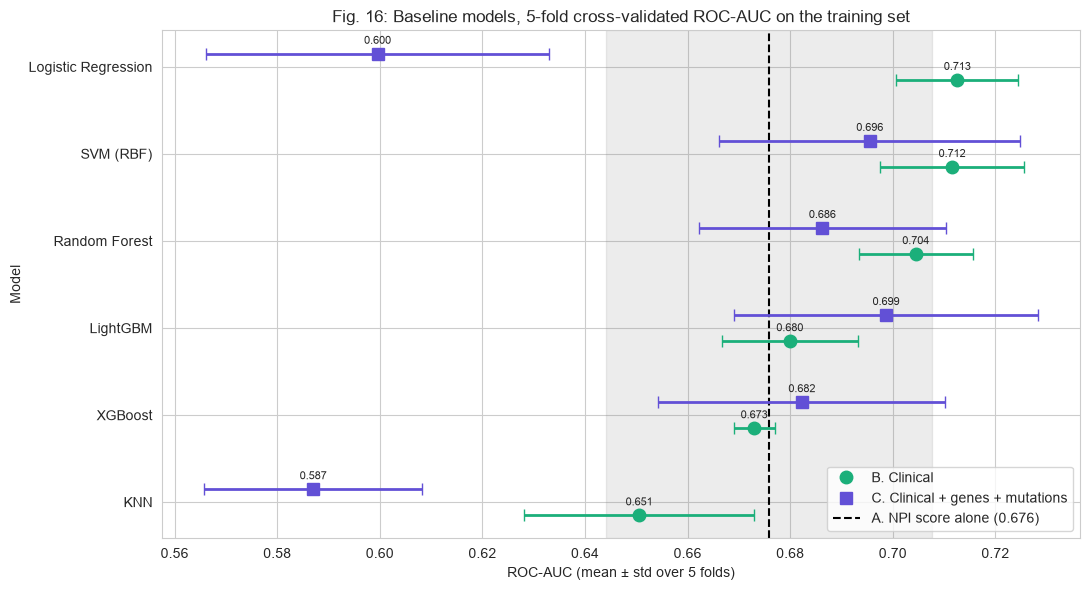

In [8]:
order = (baseline_results.groupby('Model')['ROC-AUC mean'].max().sort_values().index.tolist())
ypos = {m: i for i, m in enumerate(order)}
offset = {'B. Clinical': -0.15, 'C. Clinical + genes + mutations': 0.15}
style = {'B. Clinical': (CB, 'o'), 'C. Clinical + genes + mutations': (CC, 's')}

fig, ax = plt.subplots(figsize=(11, 6))
ax.axvspan(npi_auc.mean() - npi_auc.std(), npi_auc.mean() + npi_auc.std(), color='grey', alpha=0.15)
ax.axvline(npi_auc.mean(), color='black', linestyle='--')
for _, r in baseline_results.iterrows():
    colour, marker = style[r['Feature set']]
    y_ = ypos[r['Model']] + offset[r['Feature set']]
    ax.errorbar(r['ROC-AUC mean'], y_, xerr=r['ROC-AUC std'], fmt=marker, color=colour,
                markersize=9, capsize=4, elinewidth=2)
    ax.annotate(f"{r['ROC-AUC mean']:.3f}", (r['ROC-AUC mean'], y_), textcoords='offset points',
                xytext=(0, 7), ha='center', fontsize=8)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_title('Fig. 16: Baseline models, 5-fold cross-validated ROC-AUC on the training set')
ax.set_xlabel('ROC-AUC (mean ± std over 5 folds)')
ax.set_ylabel('Model')
ax.legend(handles=[Line2D([0], [0], marker='o', color=CB, linestyle='', markersize=9, label='B. Clinical'),
                   Line2D([0], [0], marker='s', color=CC, linestyle='', markersize=9,
                          label='C. Clinical + genes + mutations'),
                   Line2D([0], [0], color='black', linestyle='--',
                          label=f'A. NPI score alone ({npi_auc.mean():.3f})')],
          loc='lower right')
plt.tight_layout()
plt.show()

**Interpretation.** The three best baselines all use the clinical set B, and all set-B models except KNN reach or beat the NPI line. Adding the 515 molecular columns does not raise the best score: the best model on set C, LightGBM (0.699), stays below the best clinical models, and its error bar (± 0.030) is more than twice as wide as theirs.

**What the next cell does:** draws Fig. 17, the gain in ROC-AUC obtained by adding the genes and mutations (set C minus set B), for each model.
- Because B and C are scored on the same five folds, the difference can be computed fold by fold. The bar is the mean of the five differences, and the dots are the five individual differences.
- A bar to the right of zero means that the molecular data helped this model; to the left, that it hurt it.
- The table below the figure gives the mean gain and the number of folds (out of 5) in which C was better than B.

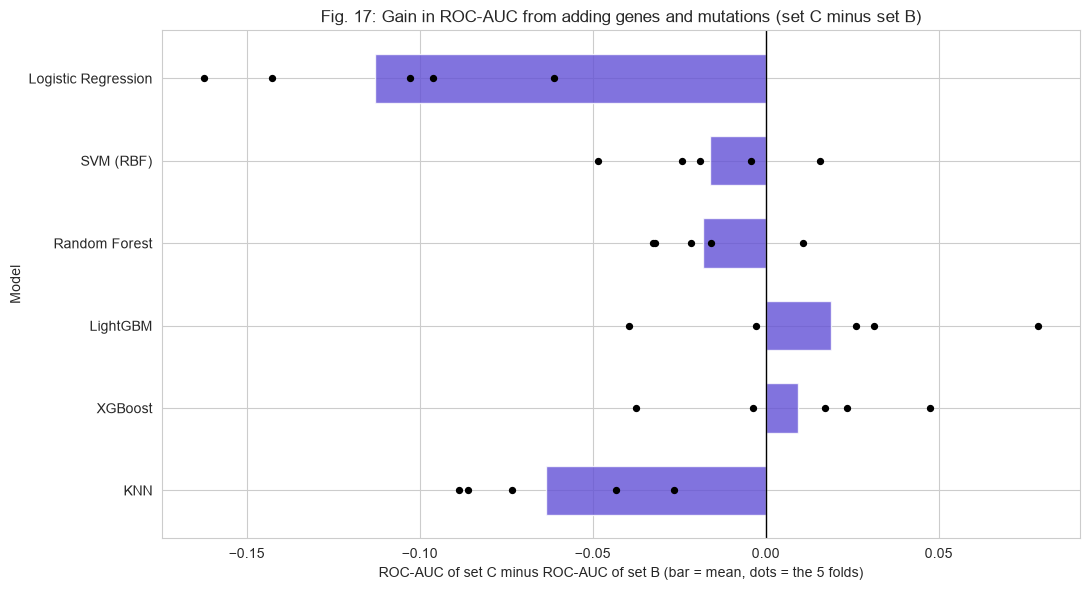

,Mean gain (C - B),Std of the gain,Folds where C > B
Logistic Regression,-0.113,0.036,0 / 5
SVM (RBF),-0.016,0.021,1 / 5
Random Forest,-0.018,0.016,1 / 5
LightGBM,0.019,0.039,3 / 5
XGBoost,0.009,0.029,3 / 5
KNN,-0.064,0.025,0 / 5


In [9]:
B, C = 'B. Clinical', 'C. Clinical + genes + mutations'
gain = pd.DataFrame({m: fold_auc[(C, m)] - fold_auc[(B, m)] for m in order})

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(range(len(order)), gain.mean().values, color=CC, alpha=0.8, height=0.6)
for i, m in enumerate(order):
    ax.scatter(gain[m].values, np.full(5, i), color='black', s=18, zorder=3)
ax.axvline(0, color='black', linewidth=1)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_title('Fig. 17: Gain in ROC-AUC from adding genes and mutations (set C minus set B)')
ax.set_xlabel('ROC-AUC of set C minus ROC-AUC of set B (bar = mean, dots = the 5 folds)')
ax.set_ylabel('Model')
plt.tight_layout()
plt.show()

gain_table = pd.DataFrame({
    'Mean gain (C - B)': gain.mean().round(3),
    'Std of the gain': gain.std(ddof=0).round(3),
    'Folds where C > B': (gain > 0).sum().astype(str) + ' / 5',
}).iloc[::-1]
gain_table

**Interpretation.** The effect of the molecular data depends on the model. It clearly hurts the two models that weigh every column in the same way: Logistic Regression loses 0.113 and KNN 0.064, in all 5 folds. With 579 columns for about 1,200 training patients per fold, they most likely fit noise; Phase 6 will check this by comparing training and validation scores. SVM and Random Forest lose slightly (about 0.02, worse in 4 folds out of 5). The two boosting models gain a little (LightGBM +0.019, XGBoost +0.009, better in 3 folds out of 5), but the gain is smaller than its standard deviation, so it is not reliable. **With default settings, genes and mutations do not improve on clinical data.**

## 5.9 Answer to the key question

**Which model gives the best baseline performance?** Logistic Regression on the clinical set B (ROC-AUC 0.713 ± 0.012), tied with SVM (0.712 ± 0.014): the gap between them is much smaller than the variation between folds. Both beat the NPI used alone (0.676 ± 0.032).

**Does this match the EDA?** Yes, on two points.
- The EDA found no single strong predictor, and a risk that rises gradually with stage, grade, positive lymph nodes and NPI (section 3.13). Gradual, roughly additive effects of this kind suit a linear model, which explains why Logistic Regression does as well as the tree ensembles on clinical data.
- The EDA also found that each gene is a weak predictor on its own (only 6 of 489 genes with |r| ≥ 0.15). Spread over 515 molecular columns, this weak signal is easily drowned in noise, which is what Fig. 17 shows for the default models.

**What this means for the next phases.**
- Phase 6 evaluates the models in more depth (confusion matrices, ROC and precision–recall curves) and compares training and validation scores to confirm the overfitting on set C.
- Phase 7 tunes the best models on both sets B and C, including the regularisation strength of Logistic Regression, so that the molecular data gets a fair chance before we answer the central question.